In [1]:
import os
import json
import pandas as pd
import numpy as np
import cv2
from scipy.signal.windows import gaussian as scipy_gaussian
from PIL import Image

import matplotlib.pyplot as plt

In [2]:
# 1. Paramètres
CSV_PATH    = "label_annotated.csv"   # votre export CSV de VIA
IMG_DIR     = "dataset_project_iapr2025/train"                # dossier de vos .JPG
OUT_DIR     = "density_maps/"                                 # dossier où sauver les .npz
SIGMA       = 150                                             # écart-type de la gaussienne
CLASS_NAMES = [
    "Jelly_White","Jelly_Milk","Jelly_Black","Amandina","Crème_brûlée",
    "Triangolo","Tentation_noir","Comtesse","Noblesse","Noir_authentique",
    "Passion_au_lait","Arabia","Stracciatella"
]

In [52]:
# 2. Mapping nom → indice
class2idx = {name: i for i, name in enumerate(CLASS_NAMES)}

In [53]:
# 3. Précompute the Gaussian kernel
kern_size = int(6 * SIGMA) | 1   # kernel size, ensure odd
g1d = scipy_gaussian(kern_size, SIGMA)
kernel2d = np.outer(g1d, g1d)
kernel2d /= kernel2d.sum()       # normalize sum to 1
half_k = kern_size // 2

In [54]:
# 4. Charger le CSV
df = pd.read_csv(CSV_PATH)

In [55]:
# 5. Créer le dossier de sortie
os.makedirs(OUT_DIR, exist_ok=True)

In [56]:
# 6. Boucle sur chaque image
for fname, group in df.groupby("filename"):
    # 6.1 Lire l'image pour connaître ses dimensions
    img_path = os.path.join(IMG_DIR, fname)
    img = cv2.imread(img_path)
    if img is None:
        print(f"[ERROR] Impossible de lire l'image : {img_path}")
        continue
    H, W = img.shape[:2]
    
    # 6.2 Initialiser le tenseur de density maps
    density = np.zeros((H, W, len(CLASS_NAMES)), dtype=np.float32)
    
    # 6.3 Pour chaque point annoté, scatter-add le kernel
    for _, row in group.iterrows():
        shape_attr = json.loads(row["region_shape_attributes"])
        x = int(shape_attr["cx"])
        y = int(shape_attr["cy"])
        choco_type = json.loads(row["region_attributes"])["Choco_Type"]
        c = class2idx.get(choco_type, None)
        if c is None:
            continue
        
        # bounds for scatter-add
        y0 = max(0,   y - half_k)
        y1 = min(H,   y + half_k + 1)
        x0 = max(0,   x - half_k)
        x1 = min(W,   x + half_k + 1)
        ky0 = half_k - (y - y0)
        ky1 = half_k + (y1 - y)
        kx0 = half_k - (x - x0)
        kx1 = half_k + (x1 - x)
        
        density[y0:y1, x0:x1, c] += kernel2d[ky0:ky1, kx0:kx1]
    
    # 6.4 Conversion en float16 pour réduire la taille
    density = density.astype(np.float16)
    
    # 6.5 Sauvegarder au format compressé .npz
    out_path = os.path.join(OUT_DIR, fname.replace(".JPG", ".npz"))
    np.savez_compressed(out_path, density=density)
    
    print(f"Saved compressed density map for {fname} → {out_path}")


Saved compressed density map for L1000756.JPG → density_maps/L1000756.npz
Saved compressed density map for L1000763.JPG → density_maps/L1000763.npz


KeyboardInterrupt: 

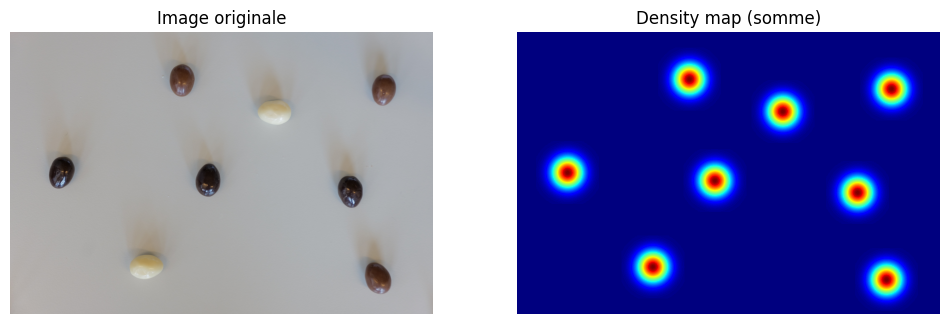

Nombre estimé d'objets sur l'image : 7.758


In [3]:
# exemple de chargement d'une density map et de l'image correspondante
npz = np.load("density_maps/L1000763.npz")
density = npz["density"]    # shape (H, W, n_classes)
img = cv2.imread("dataset_project_iapr2025/train/L1000763.JPG")[:,:,::-1]

# visualisation de la somme sur les canaux (densité totale)
total_density = density.sum(axis=-1)

fig, axes = plt.subplots(1,2, figsize=(12,5))
axes[0].imshow(img); axes[0].set_title("Image originale"); axes[0].axis("off")
axes[1].imshow(total_density, cmap="jet"); axes[1].set_title("Density map (somme)"); axes[1].axis("off")
plt.show()

# vérifiez aussi la somme pour estimer le nombre d'objets
print("Nombre estimé d'objets sur l'image :", total_density.sum())


# Neural network :

In [3]:
import os
import json
import random
from glob import glob

import cv2
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from tqdm import tqdm

In [4]:
# ─── 1. CONFIG ────────────────────────────────────────────────────────────────
DM_DIR      = "density_maps"
N_CLASSES = len(CLASS_NAMES)
DEVICE    = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH     = 4
EPOCHS    = 30
LR        = 1e-4
SEED      = 42

# Réglage du seed
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

CSV_PATH    = "dataset_project_iapr2025/train.csv"
TRAIN_DIR   = "dataset_project_iapr2025/train/"
MODEL_PATH  = "choco_count_model.pth"
OUTPUT_CSV  = "submission.csv"
IMG_SIZE    = 1024
BATCH_SIZE  = 32
LR          = 1e-3
WIDTH_MULT  = 1.0
N_EPOCHS    = 50
DEVICE      = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

Using device: cpu


In [5]:
class ChocolateCountDataset(Dataset):
    def __init__(self, csv_path, img_dir, img_size=160, train=True):
        df = pd.read_csv(csv_path)
        self.ids     = df['id'].astype(str).tolist()
        self.counts  = df.iloc[:,1:].values.astype(np.float32)
        self.classes = list(df.columns[1:])
        self.img_dir = img_dir
        self.train   = train
        aug = [transforms.Resize((img_size,img_size)),
               transforms.RandomHorizontalFlip(),
               transforms.RandomRotation(20),
               transforms.ToTensor(),
               transforms.Normalize([0.485,0.456,0.406],
                                    [0.229,0.224,0.225])]
        noaug = [transforms.Resize((img_size,img_size)),
                 transforms.ToTensor(),
                 transforms.Normalize([0.485,0.456,0.406],
                                      [0.229,0.224,0.225])]
        self.transform = transforms.Compose(aug if train else noaug)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        img_id = self.ids[idx]
        img    = Image.open(os.path.join(self.img_dir, f"L{img_id}.JPG")).convert("RGB")
        x      = self.transform(img)
        y      = torch.from_numpy(self.counts[idx])
        return x, y

from torch.utils.data import Subset, random_split, DataLoader

# 1. Instancie deux datasets distincts
ds_train = ChocolateCountDataset(CSV_PATH, TRAIN_DIR, IMG_SIZE, train=True)
ds_val   = ChocolateCountDataset(CSV_PATH, TRAIN_DIR, IMG_SIZE, train=False)

# 2. Prépare les indices de split
total_size = len(ds_train)
train_size = int(0.8 * total_size)
val_size   = total_size - train_size

# 3. Tire aléatoirement les indices
train_indices, val_indices = random_split(
    list(range(total_size)),
    [train_size, val_size]
)

# 4. Crée les Subset
train_subset = Subset(ds_train, train_indices)
val_subset   = Subset(ds_val,   val_indices)

# 5. DataLoaders
train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_subset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

In [6]:
class PatchEmbedding(nn.Module):
    def __init__(self, img_size=6000, patch_size=50, in_chans=3, embed_dim=256):
        super().__init__()
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):
        x = self.proj(x)
        x = x.flatten(2).transpose(1, 2)
        return x

class TransformerEncoder(nn.Module):
    def __init__(self, embed_dim=256, num_heads=4, mlp_ratio=4.0, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = nn.MultiheadAttention(embed_dim, num_heads, dropout=dropout, batch_first=True)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, int(embed_dim * mlp_ratio)),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(int(embed_dim * mlp_ratio), embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        x = x + self.attn(self.norm1(x), self.norm1(x), self.norm1(x))[0]
        x = x + self.mlp(self.norm2(x))
        return x

class VisionTransformerRegression(nn.Module):
    def __init__(self, img_size=6000, patch_size=50, in_chans=3, num_outputs=13, embed_dim=256, depth=6, num_heads=4):
        super().__init__()
        self.patch_embed = PatchEmbedding(img_size, patch_size, in_chans, embed_dim)
        num_patches = (img_size // patch_size) * (4000 // patch_size)

        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))
        self.pos_drop = nn.Dropout(p=0.1)

        self.blocks = nn.Sequential(
            *[TransformerEncoder(embed_dim, num_heads) for _ in range(depth)]
        )

        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_outputs)

        self._init_weights()

    def _init_weights(self):
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.xavier_uniform_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def forward(self, x):
        B = x.size(0)
        x = self.patch_embed(x)

        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)
        x = x + self.pos_embed[:, :x.size(1), :]
        x = self.pos_drop(x)

        x = self.blocks(x)
        x = self.norm(x)
        cls_output = x[:, 0]
        counts = self.head(cls_output)
        return counts

# Example usage
model = VisionTransformerRegression()
param_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters: {param_count / 1e6:.2f}M")

Total trainable parameters: 9.12M


In [7]:
# ─── 4. LOSS, OPTI, SCHEDULER ───────────────────────────────────────────────────
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,
                                                       mode='min',
                                                       factor=0.5,
                                                       patience=3,
                                                       verbose=True)

c:\Users\Utilisateur\OneDrive\Bureau\Cours\EPFL\MA2\IAPR\venv_IAPR\lib\site-packages\torch\optim\lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


In [8]:
# ─── 5. FONCTIONS D’ENTRAÎNEMENT & ÉVAL ─────────────────────────────────────────
def train_epoch(loader, model, criterion, optimizer):
    model.train()
    running_loss = 0.0
    for imgs, dms in tqdm(loader, desc="Train", leave=False):
        imgs = imgs.to(DEVICE)
        dms  = dms.to(DEVICE)
        preds = model(imgs)
        print('Preds', preds.shape)
        print('dms', dms.shape)
        loss  = criterion(preds, dms)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * imgs.size(0)
    return running_loss / len(loader.dataset)

def eval_epoch(loader, model, criterion):
    model.eval()
    running_loss = 0.0
    mae_per_class = torch.zeros(N_CLASSES, device=DEVICE)
    with torch.no_grad():
        for imgs, dms in tqdm(loader, desc="Eval", leave=False):
            imgs = imgs.to(DEVICE)
            dms  = dms.to(DEVICE)             # shape (B, C)
            preds = model(imgs)               # shape (B, C)
            running_loss += criterion(preds, dms).item() * imgs.size(0)

            # MAE par classe
            mae_per_class += torch.abs(preds - dms).sum(dim=0)

    loss = running_loss / len(loader.dataset)
    mae  = (mae_per_class / len(loader.dataset)).cpu().numpy()  # vecteur (C,)
    return loss, mae


In [ ]:
# ─── 6. BOUCLE PRINCIPALE ───────────────────────────────────────────────────────
best_val_loss = float('inf')
for epoch in range(1, EPOCHS+1):
    tr_loss = train_epoch(train_loader, model, criterion, optimizer)
    val_loss, val_mae = eval_epoch(val_loader, model, criterion)
    scheduler.step(val_loss)

    print(f"Époch {epoch:02d} | Train Loss: {tr_loss:.4f} "
          f"| Val Loss: {val_loss:.4f} | Mean MAE: {val_mae.mean():.3f}")

    # sauvegarde du meilleur modèle (sur la loss de validation)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_ViT.pth")
        print("→ Modèle sauvegardé!")

Train:   0%|          | 0/3 [00:00<?, ?it/s]

Preds torch.Size([32, 13])
dms torch.Size([32, 13])


Train:  33%|███▎      | 1/3 [00:44<01:28, 44.39s/it]

In [ ]:
# ─── 7. TEST FINAL ───────────────────────────────────────────────────────────────
model.load_state_dict(torch.load("best_choco_unet.pth"))
test_loss, test_mae = eval_epoch(test_loader, model, criterion)
print(f"\n=== TEST FINAL ===\nTest Loss: {test_loss:.4f} "
      f"| MAE par classe:\n")
for cname, mae_val in zip(CLASS_NAMES, test_mae):
    print(f"  - {cname:20s}: {mae_val:.3f}")
print(f"\nMAE globale : {test_mae.mean():.3f}")